# Visualize Graph-to-State Mapping

This Visualize notebook loads the cache produced by `Generate-token-graphs-across-dynamical-complexity.ipynb` and generates the right-hand, final-layer graph-to-state mapping panels for **Attention-Induced Token-Graph Organization Across Dynamical Complexity and Context Length** in the Results.

Each row pairs the Llama-3.2-3B attention-induced token graph at $N = 500$ with its source trajectory for logistic period 64, logistic $r=4.0$, and Lorenz inputs. Matched colors link selected graph clusters to trajectory intervals; circles and triangles denote numeric and separator tokens. For period 64, a clique-like cluster appears early, before sufficient context reveals the recurrence, whereas the chaotic inputs exhibit multiple such clusters throughout their trajectories.

Set imports, retained inputs, matched-color intervals, and figure styles.


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from scipy.integrate import solve_ivp

# Analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS

PROCESSED_DATA_DIR = Path('processed_graph_data')
FIGURE_OUTPUT_DIR = Path('figure')
FIGURE_SAVE_FILENAME = 'graph-to-state-mapping.pdf'

# Retained inputs and matched graph/trajectory colors
GRAPH_TO_STATE_DATA_NAMES = ('Logistic r=3.5698', 'Logistic r=4.0', 'Lorenz')
STATIC_WINDOW_COLORS = [
    '#56B4E9',
    '#E69F00',
    '#009E73',
    '#CC79A7',
]

UNCOLORED_TOKEN_MARKER_COLOR = '#B8B8B8'
UNCOLORED_TOKEN_MARKER_ALPHA = 0.50
UNCOLORED_STATE_MARKER_SIZE = 10
UNCOLORED_DELIMITER_MARKER_SIZE = 12
UNCOLORED_MARKER_EDGE_COLOR = '#555555'
UNCOLORED_MARKER_LINEWIDTH = 0.08

# One-based token intervals shared by graph nodes and trajectories
COLOR_TOKEN_RANGES_ONE_BASED = {
    'Logistic r=3.5698': ((1, 128),),
    'Logistic r=4.0': ((1, 159), (160, 240), (241, 339), (340, 500)),
    'Lorenz': ((1, 99), (100, 250), (251, 355), (356, 500)),
}
REQUIRE_COLOR_RANGE_COVERAGE = {
    'Logistic r=3.5698': False,
    'Logistic r=4.0': True,
    'Lorenz': True,
}

# Attention-graph style
RGB_GRAPH_EDGE_BASE_GRAY = 0.05
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.46
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.24
RGB_GRAPH_EDGE_LW_SPAN = 1.35
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR = 2.5
RGB_GRAPH_MAX_EDGES_DRAW = None
RGB_GRAPH_EDGE_STYLE_BINS = 20
RGB_GRAPH_X_MARGIN = 0.02
RGB_GRAPH_Y_MARGIN = 0.04

# Graph-to-state figure layout and typography
FIGURE_SIZE = (6.02, 6.2)
DISPLAY_DPI = 150
FIGURE_DPI = 300
SAVEFIG_PAD_INCHES = 0.03
PANEL_TITLE_FONT_SIZE = 13.42
ROW_LABEL_FONT_SIZE = 13
AXIS_LABEL_FONT_SIZE = 13
AXIS_LABEL_PAD = 1.5
Y_AXIS_LABEL_PAD = 0.5
PANEL_TITLE_PAD = 11.5
ROW_LABEL_X = 0.170
TRAJECTORY_Y_TICKS_BY_DATA_NAME = {
    'Logistic r=3.5698': (0.3, 0.6, 0.9),
    'Logistic r=4.0': (0.0, 0.5, 1.0),
    'Lorenz': (-15.0, 0.0, 15.0),
}
TRAJECTORY_Y_TICK_LABELS_BY_DATA_NAME = {
    'Logistic r=3.5698': ('0.3', '0.6', '0.9'),
    'Logistic r=4.0': ('0.0', '0.5', '1.0'),
    'Lorenz': ('-15', '0', '15'),
}

REQUIRED_GRAPH_DATA_ARRAY_KEYS = (
    'layer_indices',
    'Wbar',
    'layout_positions',
    'is_delimiter',
)

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['savefig.dpi'] = FIGURE_DPI


Load and validate the processed graph archives.


In [2]:
DATA_TITLE_OVERRIDES = {
    'Logistic r=3.5698': 'Logistic period 64',
    'Logistic r=4.0': 'Logistic r=4.0',
    'Lorenz': 'Lorenz',
}


def panel_title(data_name):
    return DATA_TITLE_OVERRIDES.get(str(data_name), str(data_name))


def context_fraction_label(frac):
    # Cache filenames encode 500 tokens as context50: 50% of the 1,000-token reference.
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


def load_processed_graph_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in REQUIRED_GRAPH_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    return processed_data


def check_processed_graph_data(data_names=GRAPH_TO_STATE_DATA_NAMES, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed graph data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:\n' + details)


def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=GRAPH_TO_STATE_DATA_NAMES[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


Reconstruct the logistic and Lorenz state trajectories.


In [3]:
def lorenz(t, y, sigma, rho, beta):
    return [
        sigma * (y[1] - y[0]),
        y[0] * (rho - y[2]) - y[1],
        y[0] * y[1] - beta * y[2],
    ]


sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0
initial_conditions = [-8, 7, 27]
t_span = (0, 50)
t_eval = np.linspace(t_span[0], t_span[1], 500)

sol = solve_ivp(
    lorenz,
    t_span,
    initial_conditions,
    args=(sigma, rho, beta),
    t_eval=t_eval,
)

x_vals = sol.y[0]
N = len(x_vals)

x0 = 0.2


def logistic_sequence(r, x0, n):
    x = np.empty(n, dtype=float)
    x[0] = x0
    for i in range(1, n):
        x[i] = r * x[i - 1] * (1 - x[i - 1])
    return x


def settle_time_float(x, p, tol=1e-10):
    x = np.asarray(x, dtype=float)
    if p is None or p <= 0 or p >= x.size:
        return None
    err = np.abs(x[p:] - x[:-p])
    suffix_max = np.maximum.accumulate(err[::-1])[::-1]
    hits = np.flatnonzero(suffix_max < tol)
    return int(hits[0]) if hits.size else None


def build_burned_in_logistic_window(r, x0, n_window, expected_period=None, n_long=20000, tol=1e-10):
    if expected_period is None:
        return logistic_sequence(r, x0, n_window), 0

    x_long = logistic_sequence(r, x0, n_long)
    t_settle = settle_time_float(x_long, expected_period, tol=tol)
    if t_settle is None:
        raise ValueError(f'Could not find settle time for r={r} with expected period {expected_period}.')
    if t_settle + n_window > x_long.size:
        raise ValueError(f'Need a longer trajectory for r={r}; settle index {t_settle} leaves fewer than {n_window} states.')
    return np.asarray(x_long[t_settle:t_settle + n_window], dtype=float), int(t_settle)


logistic_period64_sequence, logistic_period64_start_index = build_burned_in_logistic_window(
    3.5698,
    x0=x0,
    n_window=N,
    expected_period=64,
)


logistic_sequences = {
    3.5698: logistic_period64_sequence,
    4.0: logistic_sequence(4.0, x0, N),
}


def context_state_count(frac=CONTEXT_FRAC, total_n=N):
    frac_use = float(frac)
    if frac_use >= 1.0:
        ctx_len = int(total_n)
    else:
        ctx_len = max(1, int(round(frac_use * (total_n - 1))))
    return min(int(total_n), ctx_len)


def original_state_series(data_name):
    if data_name == 'Lorenz':
        series = np.asarray(x_vals, dtype=float)
    elif data_name == 'Logistic r=3.5698':
        series = np.asarray(logistic_sequences[3.5698], dtype=float)
    elif data_name == 'Logistic r=4.0':
        series = np.asarray(logistic_sequences[4.0], dtype=float)
    else:
        raise KeyError(data_name)
    token_positions = 1 + 2 * np.arange(series.size, dtype=float)
    return token_positions, series, 'Token position', 'State value'


Prepare matched graph and trajectory payloads from the cached arrays.


In [4]:
def _contiguous_ranges_from_indices(indices, one_based=True):
    indices = np.asarray(indices, dtype=int)
    if indices.size == 0:
        return []
    indices = np.unique(indices)
    breaks = np.flatnonzero(np.diff(indices) > 1) + 1
    chunks = np.split(indices, breaks)
    offset = 1 if one_based else 0
    return [(int(chunk[0]) + offset, int(chunk[-1]) + offset) for chunk in chunks if chunk.size]


def token_window_groups_from_ranges(
    data_name,
    n_tokens,
    ranges_by_data_name=COLOR_TOKEN_RANGES_ONE_BASED,
    require_coverage=REQUIRE_COLOR_RANGE_COVERAGE,
):
    n_tokens = int(n_tokens)
    if n_tokens <= 0:
        return []

    if data_name not in ranges_by_data_name:
        return [group.astype(int) for group in np.array_split(np.arange(n_tokens), 4) if group.size > 0]

    if isinstance(require_coverage, dict):
        coverage_required = bool(require_coverage.get(data_name, True))
    else:
        coverage_required = bool(require_coverage)

    ranges = tuple(ranges_by_data_name[data_name])
    if len(ranges) > len(STATIC_WINDOW_COLORS):
        raise ValueError(
            f'{data_name} defines {len(ranges)} color ranges, but only {len(STATIC_WINDOW_COLORS)} colors are available.'
        )

    occupied = np.zeros(n_tokens, dtype=bool)
    window_groups = []
    for color_idx, bounds in enumerate(ranges):
        if len(bounds) != 2:
            raise ValueError(f'{data_name} color {color_idx + 1} range must be a (start, end) pair, got {bounds!r}.')
        start, end = (int(value) for value in bounds)
        if start < 1 or end > n_tokens:
            raise ValueError(
                f'{data_name} color {color_idx + 1} range ({start}, {end}) is outside the valid one-based token range 1..{n_tokens}.'
            )
        if start > end:
            raise ValueError(f'{data_name} color {color_idx + 1} has start > end: ({start}, {end}).')

        group = np.arange(start - 1, end, dtype=int)
        if np.any(occupied[group]):
            overlaps = _contiguous_ranges_from_indices(group[occupied[group]])
            raise ValueError(f'{data_name} color {color_idx + 1} overlaps existing color ranges at token ranges {overlaps}.')
        occupied[group] = True
        window_groups.append(group)

    if coverage_required and not np.all(occupied):
        missing = _contiguous_ranges_from_indices(np.flatnonzero(~occupied))
        raise ValueError(f'{data_name} color ranges leave uncolored one-based token ranges: {missing}.')

    return window_groups


def build_token_state_mapping(is_delimiter, state_count):
    is_delimiter = np.asarray(is_delimiter, dtype=bool)
    state_count = int(state_count)
    state_token_indices = np.flatnonzero(~is_delimiter)[:state_count]

    token_to_state_index = np.full(is_delimiter.shape[0], -1, dtype=int)
    token_to_state_index[state_token_indices] = np.arange(state_token_indices.size, dtype=int)

    delimiter_token_indices = np.flatnonzero(is_delimiter)
    counts_before = np.searchsorted(state_token_indices, delimiter_token_indices, side='left')
    prev_state_index = counts_before - 1
    next_state_index = counts_before
    valid_segments = (prev_state_index >= 0) & (next_state_index < state_token_indices.size)

    delimiter_segment_token_indices = delimiter_token_indices[valid_segments].astype(int)
    if np.any(valid_segments):
        delimiter_segment_pairs = np.column_stack([
            prev_state_index[valid_segments],
            next_state_index[valid_segments],
        ]).astype(int)
    else:
        delimiter_segment_pairs = np.zeros((0, 2), dtype=int)

    return token_to_state_index, delimiter_segment_token_indices, delimiter_segment_pairs


def collect_graph_to_state_payloads(layer_index, data_names=GRAPH_TO_STATE_DATA_NAMES, frac=CONTEXT_FRAC):
    payloads = []
    all_edge_weights = []
    ctx_len = context_state_count(frac=frac, total_n=N)

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=PROCESSED_DATA_DIR)
        offset = layer_offset(processed_data, layer_index)

        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        layout_positions = np.asarray(processed_data['layout_positions'], dtype=np.float32)[offset]
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

        _, _, w_edges = select_top_edges(
            Wbar,
            max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
            threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
        )
        if w_edges.size:
            all_edge_weights.append(w_edges)

        time_all, state_all, x_label, y_label = original_state_series(data_name)
        state_count = min(ctx_len, int((~is_delimiter).sum()), time_all.size, state_all.size)
        token_to_state_index, delimiter_token_indices, delimiter_segment_pairs = build_token_state_mapping(
            is_delimiter,
            state_count=state_count,
        )

        payloads.append(
            dict(
                data_name=data_name,
                title=panel_title(data_name),
                Wbar=Wbar,
                layout_positions=layout_positions,
                is_delimiter=is_delimiter,
                time_axis=np.asarray(time_all[:state_count], dtype=float),
                state_values=np.asarray(state_all[:state_count], dtype=float),
                x_label=x_label,
                y_label=y_label,
                token_to_state_index=token_to_state_index,
                delimiter_segment_token_indices=delimiter_token_indices,
                delimiter_segment_pairs=delimiter_segment_pairs,
                window_groups=token_window_groups_from_ranges(data_name, is_delimiter.shape[0]),
            )
        )

    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return payloads, edge_weight_limits


Prepare and draw attention-induced token graphs.


In [5]:
def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)


def select_top_edges(W, max_edges=None, threshold=None, threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')

    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    iu = np.triu_indices(n, k=1)
    w = W[iu]

    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor) if threshold is None else float(threshold)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    pos_idx = np.nonzero(pos_mask)[0]
    w_pos = w[pos_mask]

    if max_edges is None:
        chosen = pos_idx
    else:
        k = min(int(max_edges), w_pos.size)
        if k <= 0:
            return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
        if k < w_pos.size:
            top_local = np.argpartition(w_pos, -k)[-k:]
            chosen = pos_idx[top_local]
        else:
            chosen = pos_idx

    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


def draw_static_graph_on_ax(
    ax,
    W,
    xy,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
    max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
    edge_weight_limits=None,
):
    W = np.asarray(W, dtype=float)
    xy = np.asarray(xy, dtype=float)
    n = min(W.shape[0], xy.shape[0])
    if n == 0:
        ax.axis('off')
        return {'n': 0, 'edge_count': 0}

    W = W[:n, :n]
    xy = xy[:n]
    x = xy[:, 0]
    y = xy[:, 1]

    i_idx, j_idx, w_edges = select_top_edges(
        W,
        max_edges=max_edges,
        threshold_factor=edge_threshold_factor,
    )

    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)

        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins

        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=1))

    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}


Prepare trajectory overlays and assemble the graph-to-state mapping panels.


In [6]:
def overlay_static_token_windows(ax_graph, ax_traj, payload):
    xy = np.asarray(payload['layout_positions'], dtype=float)
    is_delimiter = np.asarray(payload['is_delimiter'], dtype=bool)
    token_to_state_index = np.asarray(payload['token_to_state_index'], dtype=int)
    delimiter_token_indices = np.asarray(payload['delimiter_segment_token_indices'], dtype=int)
    delimiter_segment_pairs = np.asarray(payload['delimiter_segment_pairs'], dtype=int)

    x = xy[:, 0]
    y = xy[:, 1]

    colored_token_mask = np.zeros(is_delimiter.shape[0], dtype=bool)
    for group_tokens in payload['window_groups']:
        group_tokens = np.asarray(group_tokens, dtype=int)
        group_tokens = group_tokens[(group_tokens >= 0) & (group_tokens < is_delimiter.shape[0])]
        colored_token_mask[group_tokens] = True

    uncolored_tokens = np.flatnonzero(~colored_token_mask)
    uncolored_state_tokens = uncolored_tokens[~is_delimiter[uncolored_tokens]]
    uncolored_delimiter_tokens = uncolored_tokens[is_delimiter[uncolored_tokens]]

    if uncolored_state_tokens.size > 0:
        ax_graph.scatter(
            x[uncolored_state_tokens],
            y[uncolored_state_tokens],
            s=UNCOLORED_STATE_MARKER_SIZE,
            c=UNCOLORED_TOKEN_MARKER_COLOR,
            alpha=UNCOLORED_TOKEN_MARKER_ALPHA,
            edgecolors=UNCOLORED_MARKER_EDGE_COLOR,
            linewidths=UNCOLORED_MARKER_LINEWIDTH,
            marker='o',
            zorder=2.6,
            clip_on=False,
        )
        uncolored_state_indices = token_to_state_index[uncolored_state_tokens]
        uncolored_state_indices = np.unique(uncolored_state_indices[uncolored_state_indices >= 0])
        if uncolored_state_indices.size > 0:
            ax_traj.scatter(
                payload['time_axis'][uncolored_state_indices],
                payload['state_values'][uncolored_state_indices],
                s=15,
                c=UNCOLORED_TOKEN_MARKER_COLOR,
                alpha=0.50,
                edgecolors='white',
                linewidths=0.15,
                marker='o',
                zorder=2.2,
            )
    if uncolored_delimiter_tokens.size > 0:
        ax_graph.scatter(
            x[uncolored_delimiter_tokens],
            y[uncolored_delimiter_tokens],
            s=UNCOLORED_DELIMITER_MARKER_SIZE,
            c=UNCOLORED_TOKEN_MARKER_COLOR,
            alpha=UNCOLORED_TOKEN_MARKER_ALPHA,
            edgecolors=UNCOLORED_MARKER_EDGE_COLOR,
            linewidths=UNCOLORED_MARKER_LINEWIDTH,
            marker='^',
            zorder=2.5,
            clip_on=False,
        )

    for group_idx, group_tokens in enumerate(payload['window_groups']):
        color = STATIC_WINDOW_COLORS[group_idx % len(STATIC_WINDOW_COLORS)]
        group_tokens = group_tokens[group_tokens < is_delimiter.shape[0]]
        group_state_tokens = group_tokens[~is_delimiter[group_tokens]]
        group_delimiter_tokens = group_tokens[is_delimiter[group_tokens]]

        if group_state_tokens.size > 0:
            ax_graph.scatter(
                x[group_state_tokens],
                y[group_state_tokens],
                s=13,
                c=color,
                alpha=0.72,
                edgecolors='#111111',
                linewidths=0.09,
                marker='o',
                zorder=4,
                clip_on=False,
            )
        if group_delimiter_tokens.size > 0:
            ax_graph.scatter(
                x[group_delimiter_tokens],
                y[group_delimiter_tokens],
                s=15,
                c=color,
                alpha=0.64,
                edgecolors='#111111',
                linewidths=0.08,
                marker='^',
                zorder=3,
                clip_on=False,
            )

        group_state_indices = token_to_state_index[group_state_tokens]
        group_state_indices = np.unique(group_state_indices[group_state_indices >= 0])
        if group_state_indices.size > 0:
            ax_traj.scatter(
                payload['time_axis'][group_state_indices],
                payload['state_values'][group_state_indices],
                s=22,
                c=color,
                alpha=0.98,
                edgecolors='white',
                linewidths=0.20,
                zorder=4 + group_idx,
            )

        if delimiter_segment_pairs.size > 0 and group_delimiter_tokens.size > 0:
            segment_mask = np.isin(delimiter_token_indices, group_delimiter_tokens, assume_unique=False)
            if np.any(segment_mask):
                segment_pairs = delimiter_segment_pairs[segment_mask]
                selected_segments = np.stack([
                    np.column_stack([
                        payload['time_axis'][segment_pairs[:, 0]],
                        payload['state_values'][segment_pairs[:, 0]],
                    ]),
                    np.column_stack([
                        payload['time_axis'][segment_pairs[:, 1]],
                        payload['state_values'][segment_pairs[:, 1]],
                    ]),
                ], axis=1)
                ax_traj.add_collection(
                    LineCollection(selected_segments, colors=color, linewidths=1.8, alpha=0.76, zorder=3 + group_idx)
                )


def draw_static_trajectory_on_ax(ax, payload, show_x_axis=True):
    time_axis = payload['time_axis']
    state_values = payload['state_values']

    ax.plot(time_axis, state_values, color='#D7D7D7', linewidth=1.0, alpha=0.75, zorder=1)

    x_pad = 0.02 * (time_axis[-1] - time_axis[0] if time_axis[-1] != time_axis[0] else 1.0)
    data_name = payload['data_name']
    y_min = float(np.min(state_values))
    y_max = float(np.max(state_values))
    y_pad = 0.06 * (y_max - y_min if y_max != y_min else 1.0)
    ax.set_xlim(float(time_axis[0]) - x_pad, float(time_axis[-1]) + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)
    y_ticks = TRAJECTORY_Y_TICKS_BY_DATA_NAME.get(data_name)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)
        ax.set_yticklabels(TRAJECTORY_Y_TICK_LABELS_BY_DATA_NAME[data_name])
    if show_x_axis:
        ax.set_xlabel(payload['x_label'], fontsize=AXIS_LABEL_FONT_SIZE, labelpad=AXIS_LABEL_PAD)
    else:
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelbottom=False, bottom=False)
    ax.set_ylabel(payload['y_label'], fontsize=AXIS_LABEL_FONT_SIZE, labelpad=Y_AXIS_LABEL_PAD)
    ax.grid(False)
    ax.tick_params(axis='both', labelsize=AXIS_LABEL_FONT_SIZE, length=2.2, width=0.7, pad=1.5)
    if not show_x_axis:
        ax.tick_params(axis='x', labelbottom=False, bottom=False)
    for spine in ('top', 'right', 'left', 'bottom'):
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_color('#666666')
        ax.spines[spine].set_linewidth(0.7)


Validate the cache and render the graph-to-state mapping panels.


Saved: figure/graph-to-state-mapping.pdf


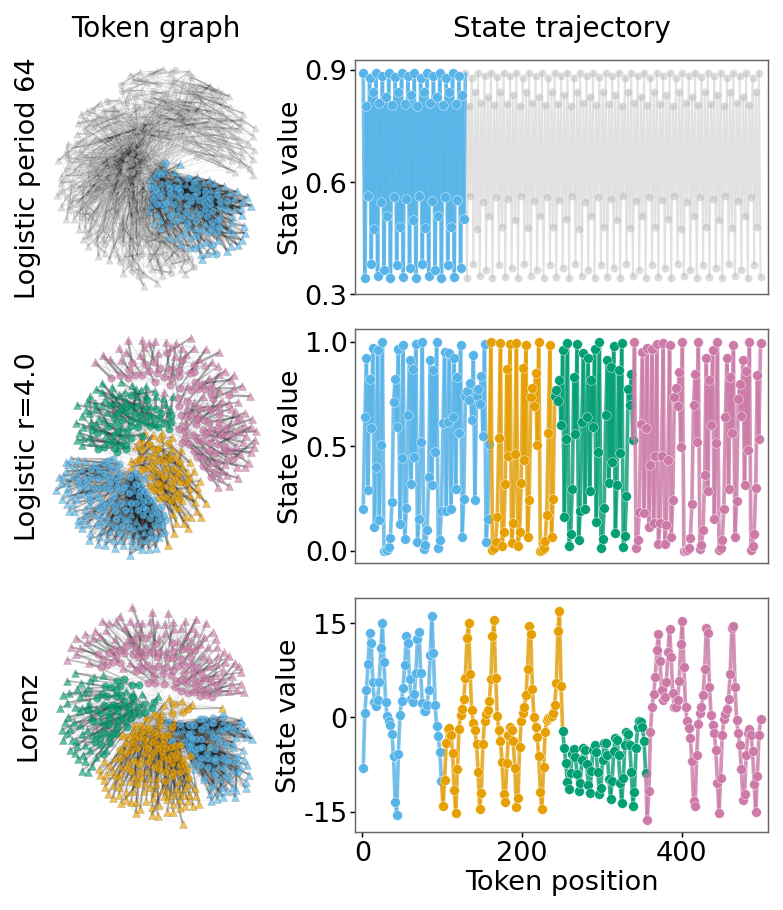

In [7]:
def plot_graph_to_state_mapping(save=True, show=True):
    check_processed_graph_data(data_names=GRAPH_TO_STATE_DATA_NAMES, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR)
    layer_index = int(available_layer_indices(GRAPH_TO_STATE_DATA_NAMES[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR)[-1])
    payloads, edge_weight_limits = collect_graph_to_state_payloads(layer_index=layer_index)

    fig, axes = plt.subplots(
        len(payloads),
        2,
        figsize=FIGURE_SIZE,
        dpi=DISPLAY_DPI,
        gridspec_kw={'width_ratios': (1.0, 1.08), 'hspace': 0.15, 'wspace': 0.02},
    )
    axes = np.atleast_2d(np.asarray(axes))

    for row, payload in enumerate(payloads):
        ax_graph = axes[row, 0]
        ax_traj = axes[row, 1]
        draw_static_graph_on_ax(
            ax_graph,
            payload['Wbar'],
            payload['layout_positions'],
            edge_weight_limits=edge_weight_limits,
            edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
        )
        draw_static_trajectory_on_ax(ax_traj, payload, show_x_axis=(row == len(payloads) - 1))
        overlay_static_token_windows(ax_graph, ax_traj, payload)

        if row == 0:
            ax_graph.set_title('Token graph', fontsize=PANEL_TITLE_FONT_SIZE, pad=PANEL_TITLE_PAD)
            ax_traj.set_title('State trajectory', fontsize=PANEL_TITLE_FONT_SIZE, pad=PANEL_TITLE_PAD)

    fig.subplots_adjust(top=0.935, bottom=0.105, left=0.100, right=0.990)
    for row, payload in enumerate(payloads):
        row_bbox = axes[row, 0].get_position()
        row_center = 0.5 * (row_bbox.y0 + row_bbox.y1)
        fig.text(
            ROW_LABEL_X,
            row_center,
            payload['title'],
            ha='center',
            va='center',
            fontsize=ROW_LABEL_FONT_SIZE,
            rotation=90,
        )

    if save:
        FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        save_path = FIGURE_OUTPUT_DIR / FIGURE_SAVE_FILENAME
        fig.savefig(save_path, bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=FIGURE_DPI)
        print(f'Saved: {save_path}')

    if show:
        plt.show()

    return fig


plot_graph_to_state_mapping(save=True, show=True);
